# Smog City — Week 5: Data Audit and Quality Check

**Dataset:** `aqi_india_38cols_knn_final.csv` (the file used in Week 4)

## Aim
Audit the dataset before further analysis: inspect its dimensions, data types, missing values, duplicates, descriptive statistics, and AQI distribution.

**How to use:** Open in Google Colab, run cells from top to bottom, and upload the same CSV when prompted. This notebook does not overwrite the source file.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from google.colab import files
from IPython.display import display

pd.set_option("display.max_columns", 100)
print("Week 5 — Data Audit")

Week 5 — Data Audit


In [2]:
uploaded = files.upload()
filename = next(iter(uploaded))
df = pd.read_csv(filename, low_memory=False)
df.columns = df.columns.astype(str).str.strip().str.lower()

print("Loaded file:", filename)
print("Rows, columns:", df.shape)
display(df.head())
print("\nColumns:")
print(df.columns.tolist())

Saving aqi_india_38cols_knn_final.csv to aqi_india_38cols_knn_final.csv
Loaded file: aqi_india_38cols_knn_final.csv
Rows, columns: (842160, 31)


,city,state,latitude,longitude,datetime,month,day_name,is_weekend,season,time_of_day,humidity_percent,dew_point_c,wind_gusts_kmh,precipitation_mm,is_raining,heavy_rain,pressure_msl_hpa,cloud_cover_percent,pm2_5_ugm3,pm10_ugm3,co_ugm3,no2_ugm3,so2_ugm3,o3_ugm3,dust_ugm3,aod,us_aqi,aqi_category,pm25_category_india,festival_period,crop_burning_season
0,agartala,tripura,23.8315,91.2868,2022-08-05 00:00:00,8.0,friday,False,monsoon,night,91.0,25.1,11.2,0.0,False,False,1004.4,100.0,14.8,21.5,197.0,21.8,2.7,32.0,0.0,0.14,289.0,Very Unhealthy,good,False,False
1,agartala,tripura,23.8315,91.2868,2022-08-05 01:00:00,8.0,friday,False,monsoon,night,93.0,25.2,9.0,0.0,False,False,1003.9,100.0,15.7,22.8,196.0,18.5,3.0,33.0,0.0,0.14,289.0,Very Unhealthy,good,False,False
2,agartala,tripura,23.8315,91.2868,2022-08-05 02:00:00,8.0,friday,False,monsoon,night,95.0,25.2,7.6,0.0,False,False,1003.5,100.0,16.3,23.5,196.0,15.1,3.3,34.0,0.0,0.15,54.0,Moderate,good,False,False
3,agartala,tripura,23.8315,91.2868,2022-08-05 03:00:00,8.0,friday,False,monsoon,night,96.0,25.2,6.8,0.0,False,False,1003.0,100.0,17.6,25.4,197.0,14.1,3.3,32.0,0.0,0.15,54.0,Moderate,good,False,False
4,agartala,tripura,23.8315,91.2868,2022-08-05 04:00:00,8.0,friday,False,monsoon,night,97.0,25.2,6.8,0.0,False,False,1002.9,100.0,18.2,26.2,199.0,13.9,3.2,30.0,0.0,0.14,54.0,Moderate,good,False,False



Columns:
['city', 'state', 'latitude', 'longitude', 'datetime', 'month', 'day_name', 'is_weekend', 'season', 'time_of_day', 'humidity_percent', 'dew_point_c', 'wind_gusts_kmh', 'precipitation_mm', 'is_raining', 'heavy_rain', 'pressure_msl_hpa', 'cloud_cover_percent', 'pm2_5_ugm3', 'pm10_ugm3', 'co_ugm3', 'no2_ugm3', 'so2_ugm3', 'o3_ugm3', 'dust_ugm3', 'aod', 'us_aqi', 'aqi_category', 'pm25_category_india', 'festival_period', 'crop_burning_season']


In [3]:
# 1. Dataset structure and quality
print("Rows:", f"{len(df):,}")
print("Columns:", len(df.columns))
print("Duplicate rows:", f"{df.duplicated().sum():,}")
print("Total missing cells:", f"{df.isna().sum().sum():,}")

audit = pd.DataFrame({
    "data_type": df.dtypes.astype(str),
    "missing_count": df.isna().sum(),
    "missing_percent": (df.isna().mean() * 100).round(2),
    "unique_values": df.nunique(dropna=True)
}).sort_values("missing_percent", ascending=False)
display(audit)
audit.to_csv("Week5_Data_Audit.csv")
print("Saved: Week5_Data_Audit.csv")

Rows: 842,160
Columns: 31
Duplicate rows: 0
Total missing cells: 2


,data_type,missing_count,missing_percent,unique_values
city,object,0,0.0,29
state,object,0,0.0,29
latitude,float64,0,0.0,29
longitude,float64,0,0.0,29
datetime,object,0,0.0,29040
month,float64,0,0.0,12
day_name,object,0,0.0,7
is_weekend,bool,0,0.0,2
season,object,0,0.0,4
time_of_day,object,0,0.0,6


Saved: Week5_Data_Audit.csv


In [4]:
# 2. Descriptive statistics for numeric columns
numeric_df = df.select_dtypes(include=np.number)
display(numeric_df.describe().T)
numeric_df.describe().T.to_csv("Week5_Descriptive_Statistics.csv")
print("Saved: Week5_Descriptive_Statistics.csv")

,count,mean,std,min,25%,50%,75%,max
latitude,842160.0,23.129041,5.543478,8.5241,20.2961,23.8315,26.9124,31.1048
longitude,842160.0,82.769207,6.937205,72.5714,77.1734,80.9462,88.6065,94.1086
month,842160.0,6.801653,3.411504,1.0000,4.0000,7.0000,10.0000,12.0000
humidity_percent,842160.0,71.324796,21.362100,3.0000,58.0000,76.0000,89.0000,100.0000
dew_point_c,842160.0,17.160777,7.020427,-11.5000,12.1000,18.6000,23.3000,27.3000
wind_gusts_kmh,842160.0,19.270394,9.921461,3.2000,11.5000,17.3000,25.2000,55.1000
precipitation_mm,842160.0,0.197799,0.915802,0.0000,0.0000,0.0000,0.0000,51.7000
pressure_msl_hpa,842160.0,1009.489776,5.698795,979.4000,1005.4000,1009.9000,1013.8000,1028.1000
cloud_cover_percent,842160.0,50.501230,43.413480,0.0000,2.0000,47.0000,100.0000,100.0000
pm2_5_ugm3,842160.0,34.549825,29.652013,1.9000,14.7000,25.9000,44.2000,183.5000


Saved: Week5_Descriptive_Statistics.csv


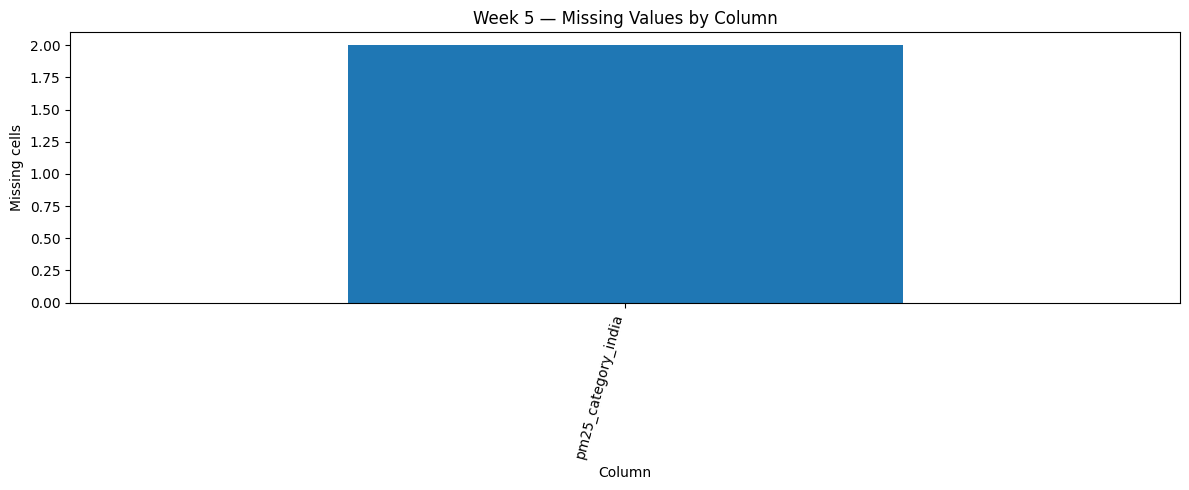

In [5]:
# 3. Missing values chart (show only columns that have missing data)
missing = df.isna().sum().sort_values(ascending=False)
missing = missing[missing > 0]

if len(missing):
    plt.figure(figsize=(12, 5))
    missing.plot(kind="bar")
    plt.title("Week 5 — Missing Values by Column")
    plt.xlabel("Column")
    plt.ylabel("Missing cells")
    plt.xticks(rotation=75, ha="right")
    plt.tight_layout()
    plt.savefig("Week5_Missing_Values.png", dpi=200)
    plt.show()
else:
    print("No missing values found.")


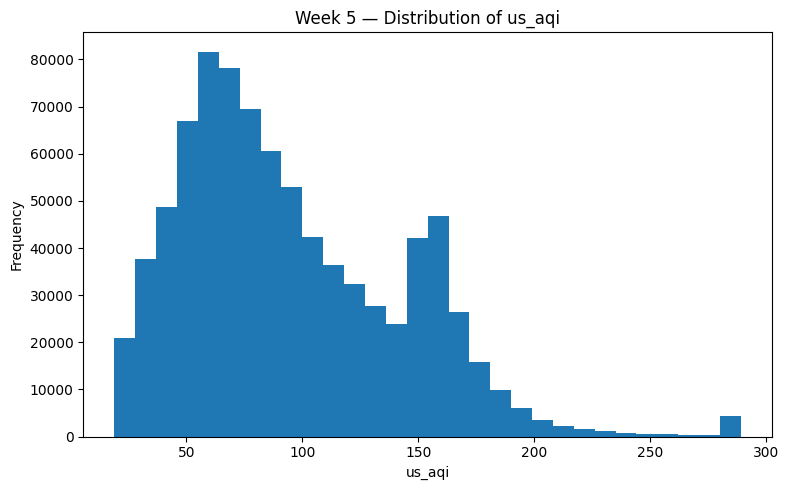

AQI column used: us_aqi


In [6]:
# 4. AQI distribution (use the AQI column if present)
aqi_candidates = ["us_aqi", "aqi", "india_aqi", "aqi_value"]
aqi_col = next((c for c in aqi_candidates if c in df.columns), None)

if aqi_col:
    aqi_values = pd.to_numeric(df[aqi_col], errors="coerce").dropna()
    plt.figure(figsize=(8, 5))
    plt.hist(aqi_values, bins=30)
    plt.title(f"Week 5 — Distribution of {aqi_col}")
    plt.xlabel(aqi_col)
    plt.ylabel("Frequency")
    plt.tight_layout()
    plt.savefig("Week5_AQI_Distribution.png", dpi=200)
    plt.show()
    print("AQI column used:", aqi_col)
else:
    print("No recognized AQI column found. Available columns:", df.columns.tolist())


In [7]:
# 5. Export a compact summary
summary = pd.DataFrame({
    "Metric": ["Rows", "Columns", "Duplicate rows", "Missing cells"],
    "Value": [len(df), len(df.columns), int(df.duplicated().sum()), int(df.isna().sum().sum())]
})
display(summary)
summary.to_csv("Week5_Summary.csv", index=False)
print("Week 5 audit complete. Outputs are saved in the Colab session.")

,Metric,Value
0,Rows,842160
1,Columns,31
2,Duplicate rows,0
3,Missing cells,2


Week 5 audit complete. Outputs are saved in the Colab session.


## Week 5 conclusion
After running all cells, write 2–4 sentences describing the actual results: dataset size, number of duplicates, whether missing values remain, and the overall shape of the AQI distribution. Use the printed results rather than assuming the data is perfect.